In [2]:
import wandb
import pandas as pd
api = wandb.Api()

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


def runs_on_task_bar_chart(runs_dict):
    df_list = []
    for group_name, runs in runs_dict.items():
        for run in runs:
            df_list.append(
                run.summary._json_dict | {
                    "name": run.name,
                    "id": run.id,
                    "tags": run.tags,
                    "group": group_name,
                    "downstream_task": run.config.get("dataset", {}).get("dataset_name"),
                    "orients_promoters": run.config.get("canonicalization", {}).get("orient_promoters", False),
                }
            )

    df = pd.DataFrame(df_list)
    groups = sorted(df["group"].dropna().unique())
    tasks = sorted(df["downstream_task"].dropna().unique())
    if "hg38" in tasks:
        tasks.remove("hg38")

    x = np.arange(len(tasks))
    width = 0.8 / len(groups)

    fig, ax = plt.subplots(figsize=(14, 5))

    def get_tasks_metric(task_df: pd.DataFrame):
        for col in ("val/mcc", "val/auroc", "val/accuracy", "val/loss"):
            if col in task_df.columns and task_df[col].notna().any():
                return task_df[col]
        return None

    bar_containers = []
    for i, group in enumerate(groups):
        vals = []
        for t in tasks:
            subset = df[(df["group"] == group) & (df["downstream_task"] == t)]
            metric = get_tasks_metric(subset)
            # Use NaN (not "skip") to keep vals aligned 1:1 with tasks
            vals.append(metric.mean() if metric is not None else np.nan)

        # Replace NaNs with 0 for plotting so bars render cleanly,
        # but remember which ones were actually missing.
        missing = np.isnan(vals)
        vals = np.nan_to_num(vals, nan=0.0)

        bars = ax.bar(x + i * width - width * len(groups) / 2, vals, width, label=group)
        bar_containers.append((bars, missing))

    # Add labels on each bar (three decimals), marking skipped/missing tasks
    for bars, missing in bar_containers:
        labels = ["skip" if m else f"{v.get_height():.2f}" if False else None for m, v in zip(missing, bars)]
        # Build labels properly: use bar height, but show "skip" where missing
        labels = []
        for bar, m in zip(bars, missing):
            labels.append("skip" if m else f"{bar.get_height():.2f}")
        ax.bar_label(bars, labels=labels, padding=3)

    ax.set_xticks(x)
    ax.set_xticklabels(tasks, rotation=45, ha="right")
    ax.set_title("Metricas por task y grupo")
    ax.legend()

    plt.tight_layout()
    plt.show()

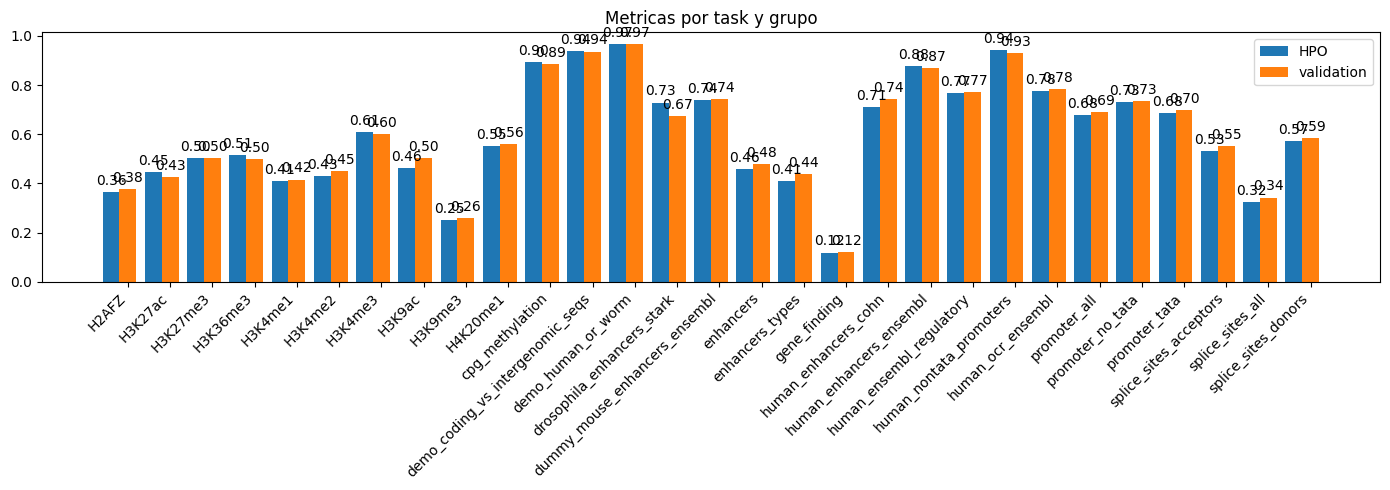

In [ ]:
hpo_runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "tags": {"$in": ["trial_11"]}
})
validation_runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "canonicalized"
})

runs_on_task_bar_chart({"HPO": hpo_runs, "validation": validation_runs})

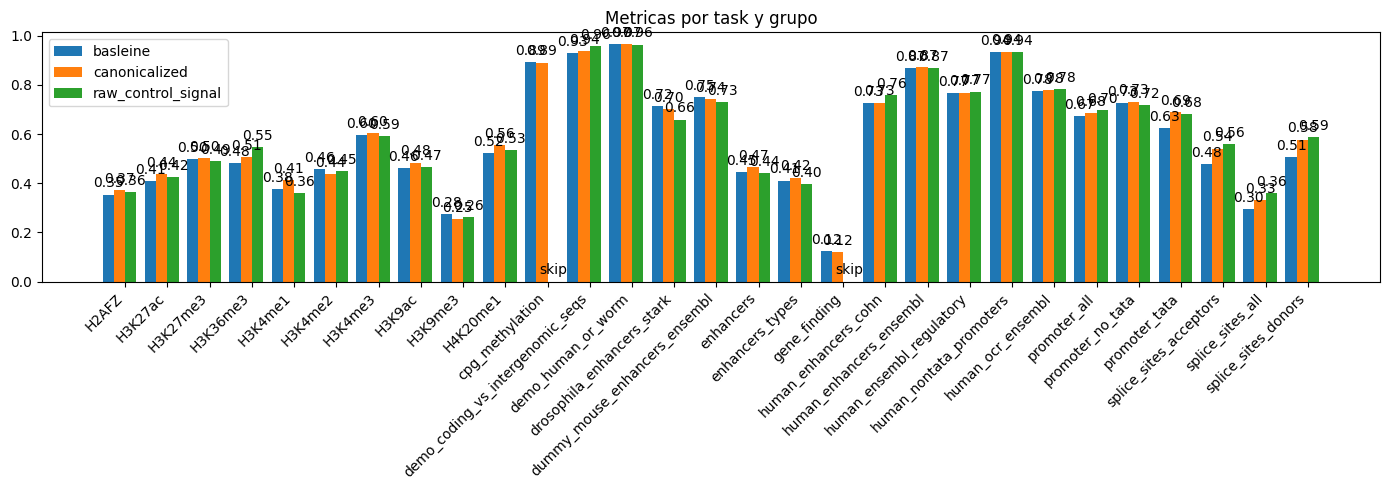

In [5]:
raw_control_signal = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "raw_control_signal"
})
canonicalized = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "canonicalized"
})
hpo_runs = api.runs("pipe-verri-gh/Canonicalization", filters={
    "tags": {"$in": ["trial_11"]}
})
baseline = api.runs("pipe-verri-gh/Canonicalization", filters={
    "group": "baseline"
})

runs_on_task_bar_chart({"canonicalized": list(canonicalized) + list(hpo_runs), "raw_control_signal": raw_control_signal, "basleine": baseline})